# Knight Ch. 40: one-dimensional quantum mechanics, read off energy diagrams

This follows Knight (5th ed.) sections 40.1–40.10 using `dgs/one_d_quantum.py`. It is written
from standard physics in Knight's notation, not copied from the book.

**One idea runs through the whole chapter:** draw U(x), draw each allowed energy as a horizontal
line, and sit ψₙ(x) on its line. That is the **energy diagram** the grader asked for on Midterm 1
Q3.4. Most questions can then be read from the picture:

| Read off the diagram | Rule |
|---|---|
| Where the particle can be classically | E > U |
| Wiggly or decaying | E > U oscillates; E < U decays over η = ħ/√(2m(U−E)) |
| How wiggly | local λ = h/√(2m(E−U)): shorter where kinetic energy is larger |
| How tall | amplitude larger where the particle moves slowly (small E−U) |
| How many nodes | ψₙ has n − 1 nodes |
| Photon wavelengths | λ = hc/\|Eᵢ − Eⱼ\| for each pair of lines |

**Conventions:** Knight numbers states from **n = 1**, including the oscillator,
Eₙ = (n − ½)ħω. Griffiths uses (n + ½)ħω with n = 0, 1, 2, … Units are nm and eV, and mass is in
units of mₑ. The useful combination is ħ²/2mₑ = 0.0381 eV·nm².

**Two links this notebook keeps visible:**
* **CS / linear algebra:** solving Schrödinger on a computer means building a tridiagonal matrix
  and finding its eigenvectors, the same operation as PCA.
* **Quantum information:** a qubit is two lines on an energy diagram, and a resonant π pulse is a
  NOT gate.

In [1]:
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import sympy as sp
sp.init_printing(use_unicode=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from dgs import one_d_quantum as Q
pd.set_option("display.width", 200)
print(f"hbar^2/2m_e = {Q.C_NM:.7f} eV nm^2,  hc = {Q.HC:.5f} eV nm")

hbar^2/2m_e = 0.0380998 eV nm^2,  hc = 1239.84198 eV nm


## 40.1 The Schrödinger equation

**Quantity:** ψ(x), a wave function whose square |ψ|² is a probability density (nm⁻¹ in 1-D).
**Equation:** −(ħ²/2m) ψ″ + U(x) ψ = E ψ. **Isolated:** ψ″ = −(2m/ħ²)(E − U) ψ.
**Units:** ħ²/2m has eV·nm², ψ″ has ψ/nm², so every term has eV·ψ. **Meaning:** curvature is
set by the kinetic energy E − U. Where E > U, ψ curves back toward the axis and oscillates.
Where E < U, it curves away and decays.

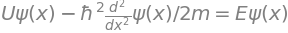

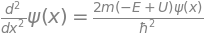

residual = 0  <=>  E = hbar**2*k**2/(2*m)   (de Broglie: p = hbar k)


In [2]:
x, k, E, U, m, hbar, kappa = sp.symbols("x k E U m hbar kappa", positive=True)
psi = sp.Function("psi")
tise = sp.Eq(-hbar**2 / (2 * m) * psi(x).diff(x, 2) + U * psi(x), E * psi(x))
display(tise)
display(sp.Eq(psi(x).diff(x, 2), sp.solve(tise, psi(x).diff(x, 2))[0]))

# free particle (U = 0): sin(kx) solves it exactly when E = hbar^2 k^2 / 2m
trial = sp.sin(k * x)
residual = sp.simplify(-hbar**2 / (2 * m) * trial.diff(x, 2) - E * trial)
display(sp.Eq(sp.Symbol("residual"), residual))
print("residual = 0  <=>  E =", sp.solve(residual / trial, E)[0], "  (de Broglie: p = hbar k)")

## 40.2 Solving the Schrödinger equation, and how a computer does it

The conditions on a physical ψ: it is continuous, ψ′ is continuous wherever U is finite, ψ → 0
where U → ∞ and as |x| → ∞, and it is normalized. Bound states exist only at the energies where
all of these can be satisfied together. That is where quantization comes from.

**The CS view.** Replace ψ″ with the finite difference (ψᵢ₊₁ − 2ψᵢ + ψᵢ₋₁)/Δx². The equation
becomes the **matrix eigenvalue problem H ψ = E ψ**, with H symmetric and tridiagonal. The
energies are eigenvalues and the wave functions are eigenvectors. This is exactly what
`Q.solve_schrodinger` does, using `numpy.linalg.eigh`.

In [3]:
t, U1, U2, U3, U4 = sp.symbols("t U_1 U_2 U_3 U_4", real=True)   # t = (hbar^2/2m)/dx^2
Us = [U1, U2, U3, U4]
H = sp.Matrix(4, 4, lambda i, j: (Us[i] + 2 * t) if i == j else (-t if abs(i - j) == 1 else 0))
display(sp.Eq(sp.Symbol("H"), H, evaluate=False))
print("symmetric:", H == H.T, "-> real eigenvalues (energies) and orthogonal eigenvectors (states)")

    ⎡U₁ + 2⋅t     -t        0         0    ⎤
    ⎢                                      ⎥
    ⎢   -t     U₂ + 2⋅t     -t        0    ⎥
H = ⎢                                      ⎥
    ⎢   0         -t     U₃ + 2⋅t     -t   ⎥
    ⎢                                      ⎥
    ⎣   0         0         -t     U₄ + 2⋅t⎦

symmetric: True -> real eigenvalues (energies) and orthogonal eigenvectors (states)


## 40.3 Particle in a rigid box: energies and wave functions

U = 0 for 0 < x < L, and U = ∞ outside. Inside, ψ = A sin kx + B cos kx.
**Boundary conditions do the quantizing:** ψ(0) = 0 forces B = 0, and ψ(L) = 0 forces kL = nπ.

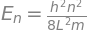

units: h^2/(m L^2) = (J s)^2/(kg m^2) = J.  Meaning: E grows as n^2 and as 1/L^2 (squeeze -> more energy).


,n,"E_n (eV), L = 1 nm","E_n (eV), L = 0.1 nm (atom-sized)"
0,1,0.376030,37.603016
1,2,1.504121,150.412065
2,3,3.384271,338.427146
3,4,6.016483,601.648260


In [4]:
L, A = sp.symbols("L A", positive=True)
n = sp.Symbol("n", integer=True, positive=True)
h = sp.Symbol("h", positive=True)
kn = n * sp.pi / L
En = sp.simplify((hbar**2 * kn**2 / (2 * m)).subs(hbar, h / (2 * sp.pi)))
display(sp.Eq(sp.Symbol("k_n"), kn), sp.Eq(sp.Symbol("E_n"), En))

norm = sp.solve(sp.Eq(sp.integrate((A * sp.sin(kn * x))**2, (x, 0, L)), 1), A)
display(sp.Eq(A, norm[0]))
print("units: h^2/(m L^2) = (J s)^2/(kg m^2) = J.  Meaning: E grows as n^2 and as 1/L^2 (squeeze -> more energy).")

rows = [(nn, Q.box_energy(nn, 1.0), Q.box_energy(nn, 0.1)) for nn in range(1, 5)]
display(pd.DataFrame(rows, columns=["n", "E_n (eV), L = 1 nm", "E_n (eV), L = 0.1 nm (atom-sized)"]))

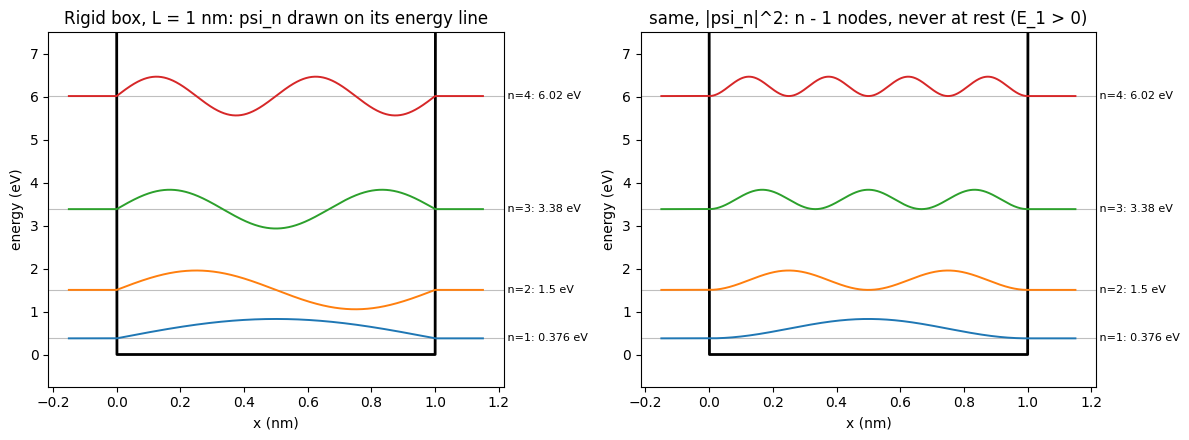

In [5]:
L0 = 1.0
xg = np.linspace(-0.15, 1.15, 1301)
Ug = np.where((xg >= 0) & (xg <= L0), 0.0, 1e9)
En_box = [Q.box_energy(nn, L0) for nn in range(1, 5)]
psis = [Q.box_psi(xg, nn, L0) for nn in range(1, 5)]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
Q.energy_diagram(a1, xg, np.clip(Ug, 0, 9), En_box, psis, U_max=7.5)
a1.set_title("Rigid box, L = 1 nm: psi_n drawn on its energy line")
Q.energy_diagram(a2, xg, np.clip(Ug, 0, 9), En_box, [p**2 for p in psis], U_max=7.5)
a2.set_title("same, |psi_n|^2: n - 1 nodes, never at rest (E_1 > 0)")
plt.tight_layout(); plt.show()

## 40.4 Interpreting the box solution, and the exam's energy-diagram method

* **Zero-point energy:** E₁ > 0. A confined particle can never be at rest; this is the uncertainty principle at work.
* **Nodes:** ψₙ has n − 1 points where the particle is *never* found.
* **Spectra:** a jump between levels emits or absorbs λ = hc/|Eᵢ − Eⱼ|. Unequal spacing gives distinct lines.

**This is the procedure the Midterm 1 Q3.4 grader wanted ("use the energy diagram"):**
1. List the levels from the diagram.
2. Keep only the levels the available energy can reach from the ground state.
3. Every downward pair among those levels gives one photon wavelength.

Example (not the exam's diagram): an electron in a 0.50 nm box, hit by a 10 eV collision.

In [6]:
Lx = 0.50
lv = [Q.box_energy(nn, Lx) for nn in range(1, 6)]
print("levels (eV):", np.round(lv, 3), "  excitation energies from n=1:", np.round(np.array(lv) - lv[0], 3))
rows = Q.transition_wavelengths(lv, max_excitation=10.0)
display(pd.DataFrame(rows, columns=["upper n", "lower n", "photon (eV)", "lambda (nm)"]).round(3))
print("Only n = 2 is reachable (n = 3 needs 12.0 eV), so there is exactly one emission line.")
print("The hydrogen formula -13.6/n^2 is never used: the levels come from THIS system's diagram.")

levels (eV): [ 1.504  6.016 13.537 24.066 37.603]   excitation energies from n=1: [ 0.     4.512 12.033 22.562 36.099]


,upper n,lower n,photon (eV),lambda (nm)
0,2,1,4.512,274.766


Only n = 2 is reachable (n = 3 needs 12.0 eV), so there is exactly one emission line.
The hydrogen formula -13.6/n^2 is never used: the levels come from THIS system's diagram.


## 40.5 The correspondence principle

A classical particle bouncing in a box spends equal time everywhere, so P_classical(0 → L/4) = 1/4.
Quantum mechanics has to agree in the limit of large n. The exact result is
P = 1/4 − sin(nπ/2)/(2nπ), which tends to 1/4 as n grows.

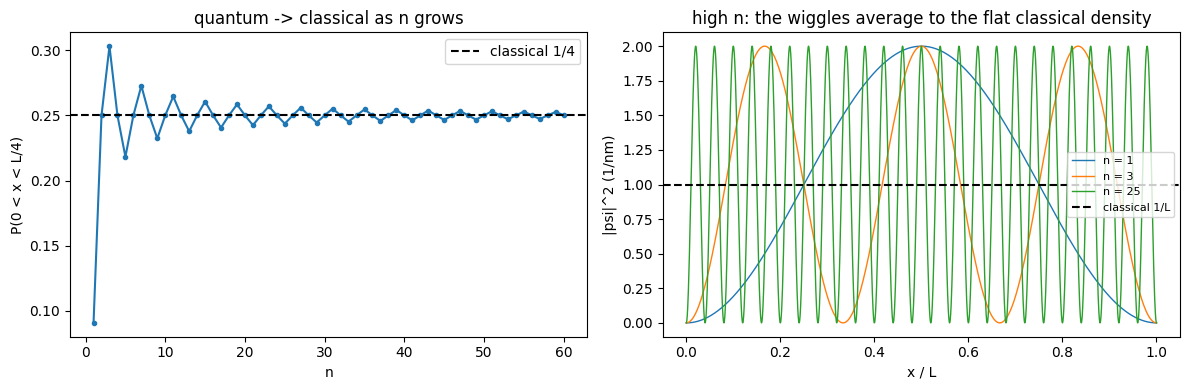

n=1: 0.0908   n=59: 0.2527


In [7]:
ns = np.arange(1, 61)
P = [Q.box_probability(int(nn), 1.0, 0, 0.25) for nn in ns]
xx = np.linspace(0, 1, 2000)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(ns, P, "o-", ms=3); a1.axhline(0.25, color="k", ls="--", label="classical 1/4")
a1.set_xlabel("n"); a1.set_ylabel("P(0 < x < L/4)"); a1.legend(); a1.set_title("quantum -> classical as n grows")
for nn in (1, 3, 25):
    a2.plot(xx, Q.box_psi(xx, nn, 1.0)**2, lw=1, label=f"n = {nn}")
a2.axhline(1.0, color="k", ls="--", label="classical 1/L")
a2.set_xlabel("x / L"); a2.set_ylabel("|psi|^2 (1/nm)"); a2.legend(fontsize=8)
a2.set_title("high n: the wiggles average to the flat classical density")
plt.tight_layout(); plt.show()
print("n=1:", round(P[0], 4), "  n=59:", round(P[58], 4))

## 40.6 Finite potential wells

The walls now have finite height U₀. Inside, ψ oscillates. Outside, ψ ∝ e^(−|x|/η) with
**penetration distance η = ħ/√(2m(U₀−E))**. Because the wave leaks into the walls, it fits in a
slightly wider effective box, so **every level sits below the rigid-box level**, and there are
only finitely many bound states. Matching ψ and ψ′ at the edges gives transcendental equations.
With z = kL/2 and z₀ = (L/2)√(2mU₀)/ħ:

$$\text{even: } z\tan z = \sqrt{z_0^2 - z^2}, \qquad \text{odd: } -z\cot z = \sqrt{z_0^2 - z^2}.$$

These are solved graphically below, then cross-checked against the matrix solver.

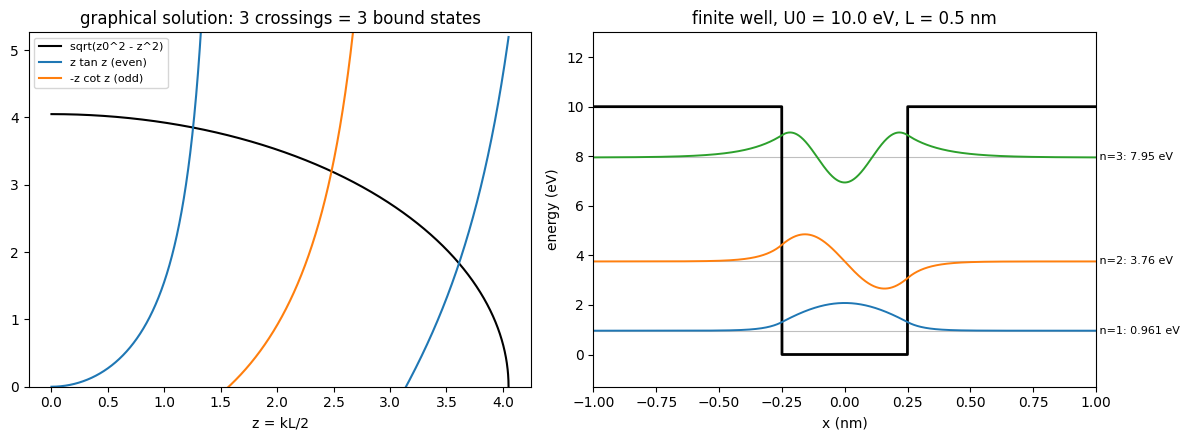

,n,transcendental (eV),matrix solver (eV),rigid box (eV),eta (nm)
0,1,0.9610,0.9610,1.5041,0.0649
1,2,3.7553,3.7552,6.0165,0.0781
2,3,7.9505,7.9504,13.5371,0.1363


In [8]:
U0, Lw = 10.0, 0.5
lvw = Q.finite_well_levels(U0, Lw)
z0 = 0.5 * Lw * math.sqrt(U0 / Q.C_NM)
zz = np.linspace(1e-3, z0, 4000)
with np.errstate(all="ignore"):
    even = zz * np.tan(zz); odd = -zz / np.tan(zz)
    even[np.abs(np.diff(np.tan(zz), prepend=0)) > 5] = np.nan
    odd[np.abs(np.diff(1 / np.tan(zz), prepend=0)) > 5] = np.nan

dx = 1e-3
xw = (np.arange(4000) + 0.5) * dx - 2.0
Uw = np.where(np.abs(xw) <= Lw / 2, 0.0, U0)
Efd, psw = Q.solve_schrodinger(xw, Uw, n_states=len(lvw))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
a1.plot(zz, np.sqrt(z0**2 - zz**2), "k", label="sqrt(z0^2 - z^2)")
a1.plot(zz, even, label="z tan z (even)"); a1.plot(zz, odd, label="-z cot z (odd)")
a1.set_ylim(0, 1.3 * z0); a1.set_xlabel("z = kL/2"); a1.legend(fontsize=8)
a1.set_title(f"graphical solution: {len(lvw)} crossings = {len(lvw)} bound states")
Q.energy_diagram(a2, xw, Uw, Efd, psw, U_max=1.3 * U0)
a2.set_xlim(-1, 1); a2.set_title(f"finite well, U0 = {U0} eV, L = {Lw} nm")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"n": range(1, len(lvw) + 1), "transcendental (eV)": lvw, "matrix solver (eV)": Efd,
                      "rigid box (eV)": [Q.box_energy(i, Lw) for i in range(1, len(lvw) + 1)],
                      "eta (nm)": [Q.penetration_depth(e, U0) for e in lvw]}).round(4))

## 40.7 Wave-function shapes

Use a lopsided potential (a box whose floor slopes up to the right), solved numerically, and
read the energy diagram:
* **wavelength** is shortest where E − U is largest (on the left), from λ = h/√(2m(E−U));
* **amplitude** is largest where E − U is smallest (on the right), because a slow particle lingers there;
* the **node count** is still n − 1.

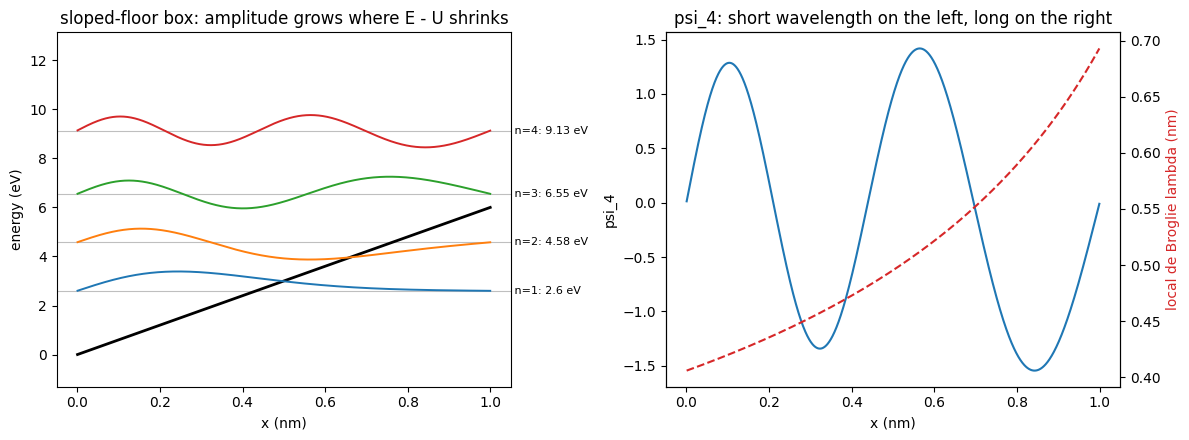

nodes per state: [0, 1, 2, 3, 4] (expected 0, 1, 2, 3, 4)


In [9]:
Ls = 1.0
xs = np.linspace(0, Ls, 1500 + 2)[1:-1]
Uslope = 6.0 * xs / Ls                 # floor rises 6 eV across the box
Es, pss = Q.solve_schrodinger(xs, Uslope, n_states=5)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
Q.energy_diagram(a1, xs, Uslope, Es[:4], pss[:4], U_max=Es[3] + 4)
a1.set_title("sloped-floor box: amplitude grows where E - U shrinks")
a2.plot(xs, pss[3], label="psi_4 (numerical)")
ax2 = a2.twinx(); ax2.plot(xs, Q.local_wavelength(Es[3], Uslope), "C3--", label="local lambda")
a2.set_xlabel("x (nm)"); a2.set_ylabel("psi_4"); ax2.set_ylabel("local de Broglie lambda (nm)", color="C3")
a2.set_title("psi_4: short wavelength on the left, long on the right")
plt.tight_layout(); plt.show()
print("nodes per state:", [Q.count_nodes(p) for p in pss], "(expected 0, 1, 2, 3, 4)")

## 40.8 The quantum harmonic oscillator

U = ½mω²x². Knight: Eₙ = (n − ½)ħω with n = 1, 2, 3, …, so the levels are **equally spaced**
by ħω. The ground state is a Gaussian ψ₁ ∝ e^(−x²/2b²) with b = √(ħ/mω). Classical turning
points are at ±√(2n−1)·b.

SymPy check (a symbolic derivation, not a proof of the model): substituting the Gaussian gives
exactly E₁ = ½ħω.

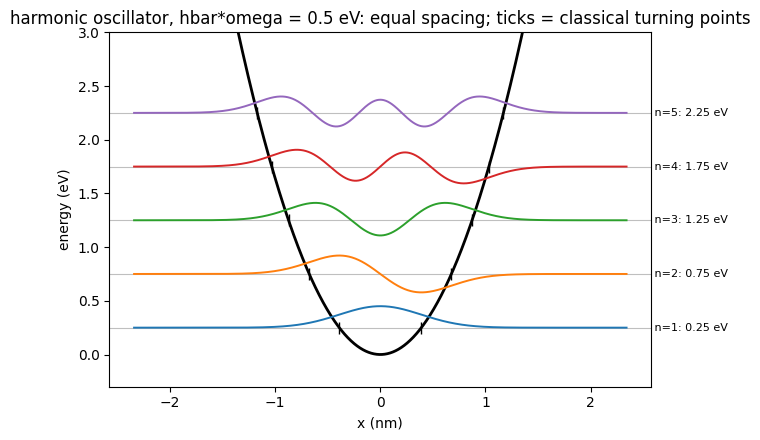

spacings (eV): [0.5     0.5     0.49999 0.49999]


In [10]:
w = sp.Symbol("omega", positive=True)
b = sp.sqrt(hbar / (m * w))
psi1 = sp.exp(-x**2 / (2 * b**2))
Hpsi = -hbar**2 / (2 * m) * psi1.diff(x, 2) + sp.Rational(1, 2) * m * w**2 * x**2 * psi1
display(sp.Eq(sp.Symbol("H psi_1 / psi_1"), sp.simplify(Hpsi / psi1)))

hw = 0.5
bb = Q.ho_length(hw)
xo = np.linspace(-6 * bb, 6 * bb, 2001)
Uo = 0.5 * hw * (xo / bb)**2
Eo, pso = Q.solve_schrodinger(xo, Uo, n_states=5)
fig, ax = plt.subplots(figsize=(7, 4.5))
Q.energy_diagram(ax, xo, Uo, Eo, pso, U_max=3.0)
for nn, e in enumerate(Eo, start=1):
    A_turn = math.sqrt(2 * nn - 1) * bb
    ax.plot([-A_turn, A_turn], [e, e], "k|", ms=8)
ax.set_title(f"harmonic oscillator, hbar*omega = {hw} eV: equal spacing; ticks = classical turning points")
plt.tight_layout(); plt.show()
print("spacings (eV):", np.round(np.diff(Eo), 5))

## 40.9 More quantum models: the double well (molecular bond / qubit)

Put two identical wells side by side, separated by a thin barrier. Each isolated well's ground
level splits into a **symmetric** state (lower, no node in the barrier) and an **antisymmetric**
state (higher, one node). Chemists call these the bonding and antibonding orbitals. The
combinations (ψ₁ ± ψ₂)/√2 are "particle on the left" and "particle on the right". A particle
started on the left tunnels back and forth with period h/ΔE.

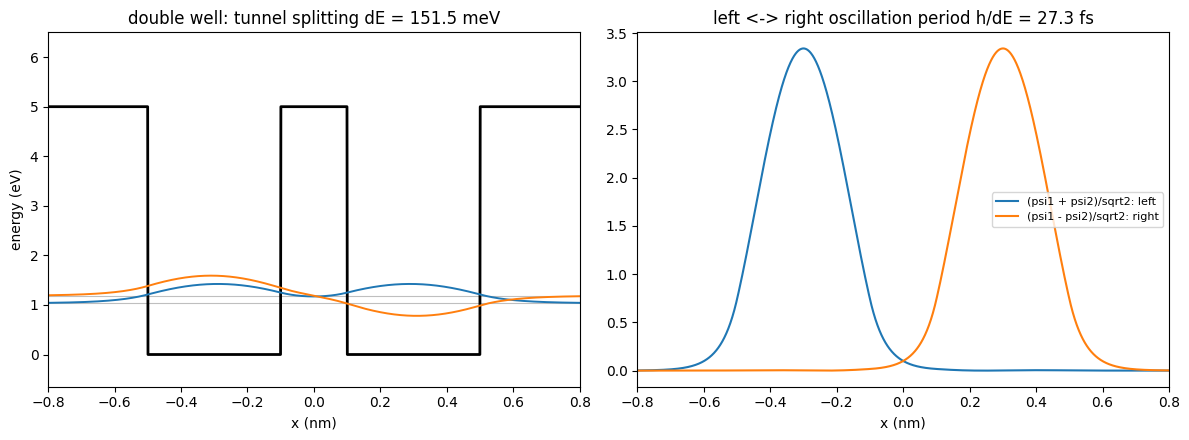

In [11]:
def double_well(x, U0=5.0, Lw=0.4, gap=0.2):
    left = np.abs(x + (gap + Lw) / 2) <= Lw / 2
    right = np.abs(x - (gap + Lw) / 2) <= Lw / 2
    return np.where(left | right, 0.0, U0)

xd = (np.arange(3000) + 0.5) * 1e-3 - 1.5
Ud = double_well(xd)
Ed, psd = Q.solve_schrodinger(xd, Ud, n_states=4)
split = Ed[1] - Ed[0]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
Q.energy_diagram(a1, xd, Ud, Ed[:2], psd[:2], scale=0.15 * (Ed[2] - Ed[0]) / np.abs(psd).max(), U_max=6.5, labels=False)
a1.set_xlim(-0.8, 0.8); a1.set_title(f"double well: tunnel splitting dE = {split * 1e3:.1f} meV")
a2.plot(xd, ((psd[0] + psd[1]) / math.sqrt(2))**2, label="(psi1 + psi2)/sqrt2: left")
a2.plot(xd, ((psd[0] - psd[1]) / math.sqrt(2))**2, label="(psi1 - psi2)/sqrt2: right")
a2.set_xlim(-0.8, 0.8); a2.legend(fontsize=8); a2.set_xlabel("x (nm)")
a2.set_title(f"left <-> right oscillation period h/dE = {Q.H_EV_S / split * 1e15:.1f} fs")
plt.tight_layout(); plt.show()

## 40.10 Quantum-mechanical tunneling

**Knight's estimate:** P_tunnel ≈ e^(−2w/η). **Exact rectangular barrier:**
T = [1 + U₀² sinh²(κw) / (4E(U₀−E))]⁻¹ with κ = 1/η. For thick barriers, T → 16E(U₀−E)/U₀² · e^(−2w/η).
Knight's estimate drops that prefactor, which is fine on a log scale.

**Engineering example, scanning tunneling microscope (STM):** an electron crosses a vacuum gap
where U₀ − E ≈ the work function (~4 eV here). Because the current goes like e^(−2w/η), a change
in gap of one atom's diameter changes the current by orders of magnitude. That is why an STM can
see single atoms.

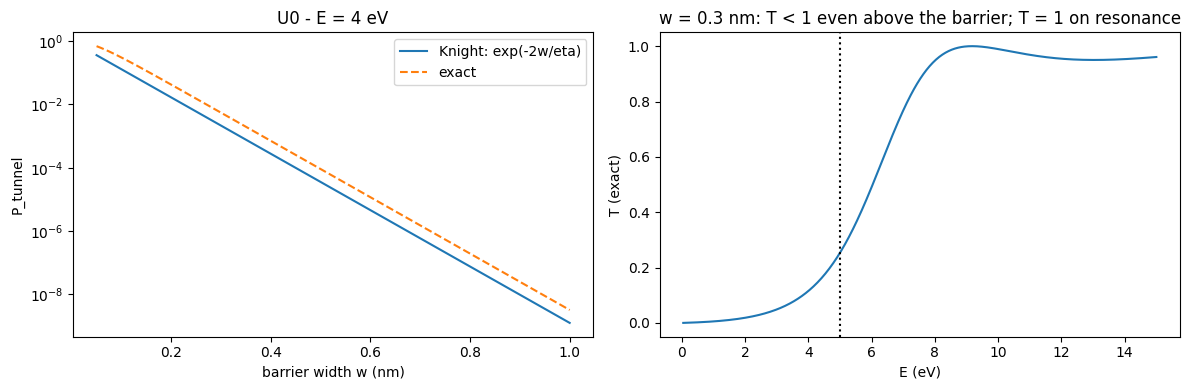

eta = 0.0976 nm; changing the gap by 0.1 nm changes the current by a factor 7.8


In [12]:
E_e, U0b = 1.0, 5.0                    # U0 - E = 4 eV
ws = np.linspace(0.05, 1.0, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.semilogy(ws, [Q.tunneling_probability(E_e, U0b, ww) for ww in ws], label="Knight: exp(-2w/eta)")
a1.semilogy(ws, [Q.tunneling_probability(E_e, U0b, ww, exact=True) for ww in ws], "--", label="exact")
a1.set_xlabel("barrier width w (nm)"); a1.set_ylabel("P_tunnel"); a1.legend(); a1.set_title("U0 - E = 4 eV")
Es_scan = np.linspace(0.05, 15, 600)
a2.plot(Es_scan, [Q.tunneling_probability(e, U0b, 0.3, exact=True) for e in Es_scan])
a2.axvline(U0b, color="k", ls=":"); a2.set_xlabel("E (eV)"); a2.set_ylabel("T (exact)")
a2.set_title("w = 0.3 nm: T < 1 even above the barrier; T = 1 on resonance")
plt.tight_layout(); plt.show()
eta = Q.penetration_depth(E_e, U0b)
print(f"eta = {eta:.4f} nm; changing the gap by 0.1 nm changes the current by a factor {math.exp(2 * 0.1 / eta):.1f}")

## Quantum information: a qubit is two lines on an energy diagram

To use levels 1 and 2 as a qubit, you drive the system at f₁₂ = (E₂ − E₁)/h. The danger is
**leakage**: if E₃ − E₂ equals E₂ − E₁, the same drive also pushes the system up to level 3.
The figure of merit is the **anharmonicity** α = (E₃ − E₂) − (E₂ − E₁):

* harmonic oscillator: α = 0, so it can't be used as a qubit. This is why superconducting
  qubits (transmons) are deliberately *an*harmonic oscillators;
* box: α = 2E₁ > 0, unequal spacing, so levels 1 and 2 can be addressed on their own.

**The logic gate.** Driving on resonance gives Rabi oscillations, P₂(t) = sin²(Ωt/2). A pulse of
length t = π/Ω swaps the two levels. That is the quantum **NOT** gate, and a π/2 pulse makes an
equal superposition. A drive detuned by Δ never fully flips the system: the maximum is Ω²/(Ω²+Δ²).
Large α means the 2→3 transition is far detuned, so the gate stays inside the qubit.

,system,f12 (THz),alpha (eV)
0,harmonic oscillator (hw=0.5 eV),120.8995,0.0000
1,rigid box 1 nm,272.7711,0.7521
2,"finite well 10 eV, 0.5 nm",675.6442,1.4010


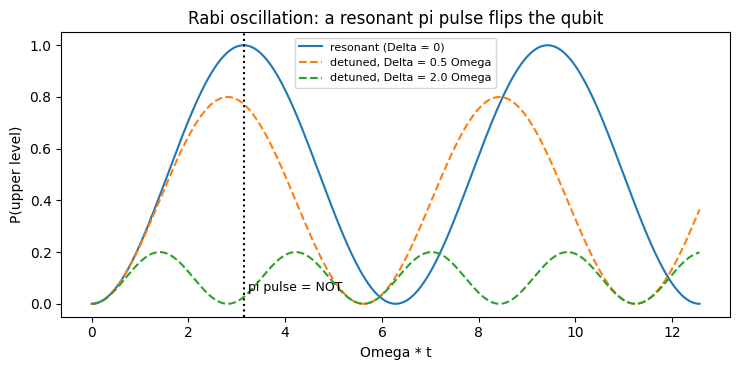

In [13]:
models = {"harmonic oscillator (hw=0.5 eV)": [Q.ho_energy(i, 0.5) for i in (1, 2, 3)],
          "rigid box 1 nm": [Q.box_energy(i, 1.0) for i in (1, 2, 3)],
          "finite well 10 eV, 0.5 nm": list(lvw[:3])}
display(pd.DataFrame([{"system": k, "f12 (THz)": Q.qubit_from_levels(v)["f01_Hz"] / 1e12,
                       "alpha (eV)": Q.qubit_from_levels(v)["alpha_eV"]} for k, v in models.items()]).round(4))

Om = 1.0
tt = np.linspace(0, 4 * math.pi, 600)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(tt, Q.rabi_population(Om, tt), label="resonant (Delta = 0)")
for d in (0.5, 2.0):
    ax.plot(tt, Q.rabi_population(Om, tt, detuning=d * Om), "--", label=f"detuned, Delta = {d} Omega")
ax.axvline(math.pi, color="k", ls=":"); ax.text(math.pi + 0.1, 0.05, "pi pulse = NOT", fontsize=9)
ax.set_xlabel("Omega * t"); ax.set_ylabel("P(upper level)"); ax.legend(fontsize=8)
ax.set_title("Rabi oscillation: a resonant pi pulse flips the qubit")
plt.tight_layout(); plt.show()

## Computer science: how accurate is the matrix solver?

The 3-point second derivative has error O(Δx²). Doubling the grid should cut the energy error
by 4. `eigh` on a dense N×N matrix costs O(N³). A tridiagonal solver costs O(N²), and for a few
eigenvalues it is cheaper still.

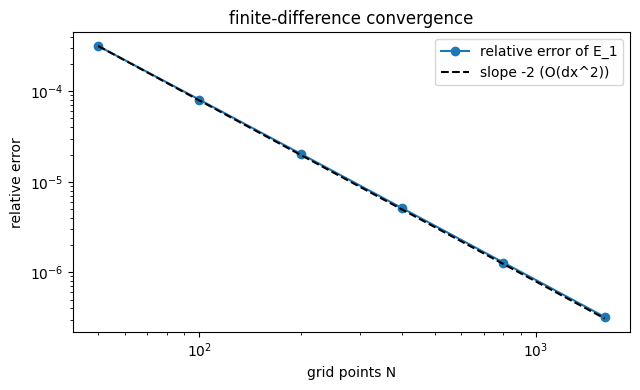

error ratio per doubling: [3.92 3.96 3.98 3.99 3.99]
eigh time (s): [0.0008 0.0027 0.0052 0.0383 0.1592 0.4234]


In [14]:
import time
Ns, errs, secs = [50, 100, 200, 400, 800, 1600], [], []
for N in Ns:
    xb = np.linspace(0, 1, N + 2)[1:-1]
    t0 = time.perf_counter(); Eb, _ = Q.solve_schrodinger(xb, 0.0, n_states=1); secs.append(time.perf_counter() - t0)
    errs.append(abs(Eb[0] / Q.box_energy(1, 1.0) - 1))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(Ns, errs, "o-", label="relative error of E_1")
ax.loglog(Ns, errs[0] * (Ns[0] / np.array(Ns))**2, "k--", label="slope -2 (O(dx^2))")
ax.set_xlabel("grid points N"); ax.set_ylabel("relative error"); ax.legend(); ax.set_title("finite-difference convergence")
plt.tight_layout(); plt.show()
print("error ratio per doubling:", np.round(np.array(errs[:-1]) / np.array(errs[1:]), 2))
print("eigh time (s):", np.round(secs, 4))

## Practice (my own problems, in the chapter's style)

1. An electron in a 0.20 nm box drops from n = 2 to n = 1. What wavelength photon is emitted?
2. In a box, P(0 → L/4) for n = 2: compute it, then explain the result from the shape of |ψ₂|².
3. An electron with E = 2 eV meets a 6 eV barrier. What is η? What width gives P_tunnel = 10⁻³?
4. An oscillator emits 1.2 eV photons in its 2 → 1 jump. What is the photon energy for 3 → 1?
5. A system has levels 0, 4.0, 7.0, and 9.0 eV, and an 8 eV electron hits it in the ground state. List every emitted wavelength.

In [15]:
print("1.", round(Q.HC / (Q.box_energy(2, 0.2) - Q.box_energy(1, 0.2)), 2), "nm")
print("2.", round(Q.box_probability(2, 1.0, 0, 0.25), 4), "= exactly 1/4: |psi_2|^2 is symmetric about L/4 within the first half")
eta3 = Q.penetration_depth(2.0, 6.0)
print(f"3. eta = {eta3:.4f} nm;  w = (eta/2) ln(1000) = {eta3 / 2 * math.log(1000):.4f} nm")
print("4.", 2 * 1.2, "eV (equal spacing: 3 -> 1 is two steps of hbar*omega)")
display(pd.DataFrame(Q.transition_wavelengths([0, 4.0, 7.0, 9.0], max_excitation=8.0),
                     columns=["upper", "lower", "photon (eV)", "lambda (nm)"]).round(2))

1. 43.96 nm
2. 0.25 = exactly 1/4: |psi_2|^2 is symmetric about L/4 within the first half
3. eta = 0.0976 nm;  w = (eta/2) ln(1000) = 0.3371 nm
4. 2.4 eV (equal spacing: 3 -> 1 is two steps of hbar*omega)


,upper,lower,photon (eV),lambda (nm)
0,2,1,4.0,309.96
1,3,1,7.0,177.12
2,3,2,3.0,413.28


## Checklist: reading any 1-D problem from its energy diagram

- [ ] Draw U(x). Mark each Eₙ as a line; ψₙ oscillates where E > U and decays where E < U.
- [ ] Check n − 1 nodes, shorter wavelength where E − U is large, larger amplitude where it is small.
- [ ] Rigid box Eₙ ∝ n²/L². Finite well levels are lower and finite in number. Oscillator levels are evenly spaced, (n − ½)ħω in Knight's convention.
- [ ] Tunneling ≈ e^(−2w/η) with η = ħ/√(2m(U−E)). It is exponentially sensitive to w.
- [ ] Spectra: list the reachable levels, then λ = hc/ΔE for each pair. Use *this system's* levels, never the hydrogen formula unless the system is hydrogen.
- [ ] Qubit: two levels with anharmonicity α ≠ 0. A resonant π pulse is a NOT gate.
- [ ] On a computer: H is a tridiagonal matrix; energies are its eigenvalues; the error is O(Δx²).